# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Raynaldi Sandy
- **Email:** raynaldisandy77@gmail.com
- **ID Dicoding:** Raynaldi Sandy

## Menentukan Pertanyaan Bisnis

Dataset yang digunakan adalah **Bike Sharing Dataset** (sistem *bike sharing* Capital Bikeshare, Washington D.C., 2011-2012). Pertanyaan disusun dengan kerangka **SMART**:

- **Pertanyaan 1:** Pada jam berapa permintaan sewa sepeda mencapai puncak pada hari kerja dibandingkan hari libur/akhir pekan sepanjang 2011-2012, dan berapa rata-rata penyewaan per jam pada jam puncak tersebut, sehingga operator dapat menentukan jadwal distribusi dan penempatan sepeda?
- **Pertanyaan 2:** Berapa persen penurunan rata-rata penyewaan harian pada cuaca berkabut/mendung dan hujan/salju ringan dibandingkan cuaca cerah di setiap musim selama 2011-2012, sehingga operator dapat merencanakan promo dan jadwal perawatan pada kondisi cuaca tertentu?
- **Pertanyaan 3:** Berapa persentase pertumbuhan total penyewaan bulanan tahun 2012 dibandingkan bulan yang sama di 2011 (Year-over-Year), dan bulan mana yang pertumbuhannya paling tinggi maupun paling rendah, sehingga operator dapat menentukan bulan prioritas untuk kampanye pemasaran?

| Elemen SMART | Penjelasan |
|---|---|
| Specific | Masing-masing fokus pada pola jam (P1), cuaca x musim (P2), dan pertumbuhan bulanan (P3) |
| Measurable | Rata-rata penyewaan per jam, persentase penurunan, persentase pertumbuhan YoY |
| Action-oriented | Penjadwalan distribusi sepeda, strategi promo/perawatan, prioritas kampanye |
| Relevant | Sejalan dengan tujuan operator: menjaga ketersediaan sepeda dan meningkatkan penyewaan |
| Time-bound | Periode 1 Januari 2011 - 31 Desember 2012 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

## Data Wrangling

### Gathering Data

#### Load day.csv dan hour.csv

In [2]:
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print('Ukuran day_df :', day_df.shape)
print('Ukuran hour_df:', hour_df.shape)
day_df.head()

Ukuran day_df : (731, 16)
Ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day.csv` berisi 731 baris (agregasi harian) dan `hour.csv` berisi 17.379 baris (agregasi per jam), keduanya mencakup 2011-2012.
- Kolom `cnt` = `casual` + `registered` adalah total penyewaan, yang menjadi metrik utama analisis.
- Nilai `temp`, `atemp`, `hum`, dan `windspeed` masih dalam bentuk ternormalisasi, sedangkan kolom kategori (`season`, `yr`, `mnth`, `weekday`, `weathersit`) masih berupa kode angka.

### Assessing Data

#### Identifying missing value, duplicate data, dan tipe data

In [4]:
for nama, df in [('day_df', day_df), ('hour_df', hour_df)]:
    print(f'=== {nama} ===')
    print('Total missing value :', df.isna().sum().sum())
    print('Jumlah data duplikat:', df.duplicated().sum())
    print('Tipe data dteday    :', df['dteday'].dtype)
    print()
day_df.info()

=== day_df ===
Total missing value : 0
Jumlah data duplikat: 0
Tipe data dteday    : str

=== hour_df ===
Total missing value : 0
Jumlah data duplikat: 0
Tipe data dteday    : str

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-nul

#### Identifying invalid value (kelembapan = 0)

In [5]:
print('day_df  - jumlah hum == 0 :', (day_df['hum'] == 0).sum())
print(day_df.loc[day_df['hum'] == 0, ['dteday', 'hum', 'temp', 'cnt']])
print()
print('hour_df - jumlah hum == 0 :', (hour_df['hum'] == 0).sum())
print('Tanggal terkait           :', hour_df.loc[hour_df['hum'] == 0, 'dteday'].unique())

day_df  - jumlah hum == 0 : 1
        dteday  hum      temp  cnt
68  2011-03-10  0.0  0.389091  623

hour_df - jumlah hum == 0 : 22
Tanggal terkait           : <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str


#### Identifying incomplete data (jam yang tidak tercatat di hour.csv)

In [6]:
jam_per_hari = hour_df.groupby('dteday').size()
print('Jumlah hari          :', jam_per_hari.size)
print('Hari dengan < 24 jam :', (jam_per_hari < 24).sum())
print('Total baris seharusnya (731 x 24):', 731 * 24)
print('Total baris yang ada             :', len(hour_df))
print('Jam yang hilang                  :', 731 * 24 - len(hour_df))

Jumlah hari          : 731
Hari dengan < 24 jam : 76
Total baris seharusnya (731 x 24): 17544
Total baris yang ada             : 17379
Jam yang hilang                  : 165


#### Identifying outlier dan konsistensi nilai

Selisih maksimum casual + registered - cnt (day) : 0
Selisih maksimum casual + registered - cnt (hour): 0
Outlier cnt       : day=  0 | hour= 505
Outlier casual    : day= 44 | hour=1192
Outlier registered: day=  0 | hour= 680
Outlier windspeed : day= 13 | hour= 342
Outlier hum       : day=  2 | hour=  22


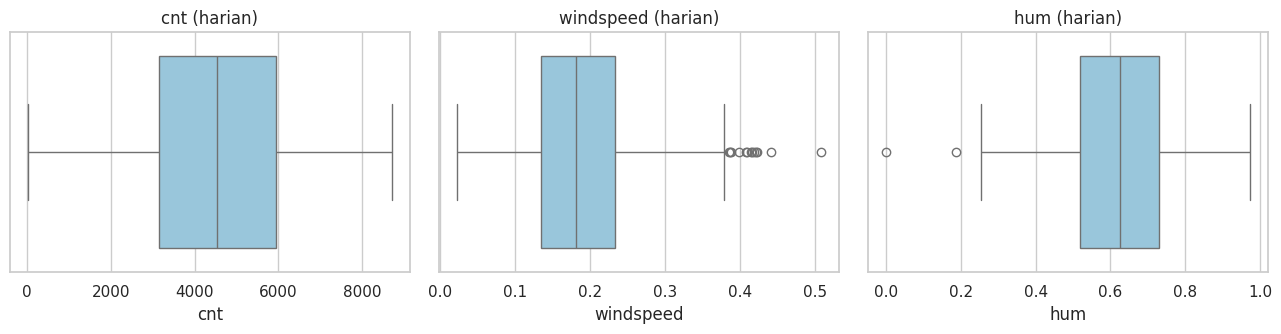

In [7]:
# Konsistensi: casual + registered harus sama dengan cnt
print('Selisih maksimum casual + registered - cnt (day) :', (day_df['casual'] + day_df['registered'] - day_df['cnt']).abs().max())
print('Selisih maksimum casual + registered - cnt (hour):', (hour_df['casual'] + hour_df['registered'] - hour_df['cnt']).abs().max())

# Outlier dengan metode IQR
def hitung_outlier(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

for kol in ['cnt', 'casual', 'registered', 'windspeed', 'hum']:
    print(f'Outlier {kol:<10}: day={hitung_outlier(day_df[kol]):>3} | hour={hitung_outlier(hour_df[kol]):>4}')

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
sns.boxplot(x=day_df['cnt'], ax=ax[0], color='#8ecae6'); ax[0].set_title('cnt (harian)')
sns.boxplot(x=day_df['windspeed'], ax=ax[1], color='#8ecae6'); ax[1].set_title('windspeed (harian)')
sns.boxplot(x=day_df['hum'], ax=ax[2], color='#8ecae6'); ax[2].set_title('hum (harian)')
plt.tight_layout(); plt.show()

**Steps to Take:**
- **Tipe data tidak sesuai:** `dteday` bertipe teks (object/str) -> ubah ke `datetime`.
- **Nilai kategori berupa kode angka & nilai ternormalisasi:** ubah kode `season`, `yr`, `mnth`, `weekday`, `weathersit`, `workingday` menjadi label yang mudah dibaca, dan kembalikan `temp`, `atemp`, `hum`, `windspeed` ke satuan aslinya (temp x 41 °C, atemp x 50 °C, hum x 100 %, windspeed x 67 km/jam).
- **Invalid value:** terdapat `hum = 0` pada 2011-03-10 (kelembapan 0% tidak masuk akal) -> ubah menjadi NaN lalu isi dengan interpolasi.
- **Data tidak lengkap:** `hour_df` kehilangan 165 jam pada 76 hari. Jam yang tidak tercatat diasumsikan tidak ada penyewaan (umumnya dini hari) -> lengkapi menjadi grid tanggal x jam dengan `cnt = 0`.
- **Outlier:** nilai ekstrem pada `casual`, `windspeed`, dan `cnt` adalah fenomena nyata (event, angin kencang, hari sepi), sehingga **tidak dihapus**.

**Insight:**
- Tidak ada missing value maupun data duplikat pada kedua dataset.
- Kolom `casual + registered = cnt` konsisten di seluruh baris.
- Masalah kualitas data yang ditemukan: tipe data, nilai tidak informatif/ternormalisasi, invalid value `hum = 0`, data jam tidak lengkap, dan outlier.

### Cleaning Data

#### Fixing tipe data, label kategori, dan skala nilai

In [8]:
label_musim = {1: 'Semi', 2: 'Panas', 3: 'Gugur', 4: 'Dingin'}
label_cuaca = {1: 'Cerah', 2: 'Berkabut/Mendung', 3: 'Hujan/Salju Ringan', 4: 'Hujan/Salju Lebat'}
label_hari = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
label_bulan = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun', 7: 'Jul', 8: 'Agu', 9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des'}

def rapikan(df):
    df = df.copy()
    df['dteday'] = pd.to_datetime(df['dteday'])
    df['season'] = df['season'].map(label_musim)
    df['yr'] = df['yr'].map({0: 2011, 1: 2012})
    df['mnth'] = df['mnth'].map(label_bulan)
    df['weekday'] = df['weekday'].map(label_hari)
    df['weathersit'] = df['weathersit'].map(label_cuaca)
    df['day_type'] = np.where(df['workingday'] == 1, 'Hari Kerja', 'Libur/Akhir Pekan')
    df['temp'] = df['temp'] * 41
    df['atemp'] = df['atemp'] * 50
    df['hum'] = df['hum'] * 100
    df['windspeed'] = df['windspeed'] * 67
    return df

day_clean = rapikan(day_df)
hour_clean = rapikan(hour_df)
day_clean[['dteday', 'season', 'yr', 'mnth', 'weekday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']].head()

,dteday,season,yr,mnth,weekday,weathersit,temp,hum,windspeed,cnt
0,2011-01-01,Semi,2011,Jan,Sabtu,Berkabut/Mendung,14.110847,80.5833,10.749882,985
1,2011-01-02,Semi,2011,Jan,Minggu,Berkabut/Mendung,14.902598,69.6087,16.652113,801
2,2011-01-03,Semi,2011,Jan,Senin,Cerah,8.050924,43.7273,16.636703,1349
3,2011-01-04,Semi,2011,Jan,Selasa,Cerah,8.200000,59.0435,10.739832,1562
4,2011-01-05,Semi,2011,Jan,Rabu,Cerah,9.305237,43.6957,12.522300,1600


#### Fixing invalid value (hum = 0)

In [9]:
for df in (day_clean, hour_clean):
    df['hum'] = df['hum'].replace(0, np.nan)

day_clean = day_clean.sort_values('dteday').reset_index(drop=True)
hour_clean = hour_clean.sort_values(['dteday', 'hr']).reset_index(drop=True)
day_clean['hum'] = day_clean['hum'].interpolate()
hour_clean['hum'] = hour_clean['hum'].interpolate()

print('Sisa hum <= 0 (day) :', (day_clean['hum'] <= 0).sum())
print('Sisa hum <= 0 (hour):', (hour_clean['hum'] <= 0).sum())
print('Missing value hum   :', day_clean['hum'].isna().sum(), hour_clean['hum'].isna().sum())

Sisa hum <= 0 (day) : 0
Sisa hum <= 0 (hour): 0
Missing value hum   : 0 0


#### Fixing data jam yang tidak lengkap

In [10]:
# Grid lengkap tanggal x jam (731 x 24 = 17.544 baris)
grid = pd.MultiIndex.from_product([day_clean['dteday'], range(24)], names=['dteday', 'hr'])
hour_full = hour_clean.set_index(['dteday', 'hr']).reindex(grid).reset_index()

# Jam yang tidak tercatat dianggap tidak ada penyewaan
for kol in ['casual', 'registered', 'cnt']:
    hour_full[kol] = hour_full[kol].fillna(0).astype(int)

# Atribut tingkat-hari dilengkapi dari day_clean
atribut_hari = ['season', 'yr', 'mnth', 'weekday', 'workingday', 'day_type', 'holiday']
hour_full = hour_full.drop(columns=atribut_hari).merge(day_clean[['dteday'] + atribut_hari], on='dteday', how='left')

# Atribut cuaca per jam untuk jam yang hilang diisi dari jam terdekat pada hari yang sama
kolom_cuaca = ['weathersit', 'temp', 'atemp', 'hum', 'windspeed']
hour_full[kolom_cuaca] = hour_full.groupby('dteday')[kolom_cuaca].transform(lambda x: x.ffill().bfill())

print('Ukuran hour_full:', hour_full.shape)
print('Missing value   :', hour_full.isna().sum().sum())
hour_full.head()

Ukuran hour_full: (17544, 18)
Missing value   : 165


,dteday,hr,instant,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season,yr,mnth,weekday,workingday,day_type,holiday
0,2011-01-01,0,1.0,Cerah,9.84,14.395,81.0,0.0,3,13,16,Semi,2011,Jan,Sabtu,0,Libur/Akhir Pekan,0
1,2011-01-01,1,2.0,Cerah,9.02,13.635,80.0,0.0,8,32,40,Semi,2011,Jan,Sabtu,0,Libur/Akhir Pekan,0
2,2011-01-01,2,3.0,Cerah,9.02,13.635,80.0,0.0,5,27,32,Semi,2011,Jan,Sabtu,0,Libur/Akhir Pekan,0
3,2011-01-01,3,4.0,Cerah,9.84,14.395,75.0,0.0,3,10,13,Semi,2011,Jan,Sabtu,0,Libur/Akhir Pekan,0
4,2011-01-01,4,5.0,Cerah,9.84,14.395,75.0,0.0,0,1,1,Semi,2011,Jan,Sabtu,0,Libur/Akhir Pekan,0


**Insight:**
- Seluruh data kini bertipe sesuai, berlabel jelas, berada pada satuan asli, dan lengkap sebanyak 731 hari x 24 jam.
- Nilai kelembapan tidak valid sudah diperbaiki, sedangkan outlier dipertahankan karena merupakan kejadian nyata.
- `day_clean` dan `hour_full` siap dipakai untuk EDA.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik dan komposisi pengguna

In [11]:
day_clean[['temp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].describe().round(2)

,temp,hum,windspeed,casual,registered,cnt
count,731.00,731.00,731.00,731.00,731.00,731.00
mean,20.31,62.89,12.76,848.18,3656.17,4504.35
std,7.51,14.06,5.19,686.62,1560.26,1937.21
min,2.42,18.79,1.50,2.00,20.00,22.00
25%,13.82,52.10,9.04,315.50,2497.00,3152.00
50%,20.43,62.75,12.13,713.00,3662.00,4548.00
75%,26.87,73.02,15.63,1096.00,4776.50,5956.00
max,35.33,97.25,34.00,3410.00,6946.00,8714.00


In [12]:
total = day_clean[['casual', 'registered', 'cnt']].sum()
print('Total penyewaan 2011-2012:', f'{total["cnt"]:,}')
print('Proporsi casual    :', f'{total["casual"] / total["cnt"]:.1%}')
print('Proporsi registered:', f'{total["registered"] / total["cnt"]:.1%}')
print()
print(day_clean.groupby('yr')['cnt'].agg(['sum', 'mean']).round(0))

Total penyewaan 2011-2012: 3,292,679
Proporsi casual    : 18.8%
Proporsi registered: 81.2%

          sum    mean
yr                   
2011  1243103  3406.0
2012  2049576  5600.0


### Explore Pertanyaan 1: pola penyewaan per jam

In [13]:
pola_jam = hour_full.pivot_table(index='hr', columns='day_type', values='cnt', aggfunc='mean').round(1)
print('Jam puncak :')
print(pola_jam.idxmax())
print('\nNilai puncak (rata-rata sewa/jam):')
print(pola_jam.max())
print('\nRata-rata pada beberapa jam kunci:')
print(pola_jam.loc[[2, 8, 12, 17]])

Jam puncak :


day_type
Hari Kerja           17
Libur/Akhir Pekan    13
dtype: int64

Nilai puncak (rata-rata sewa/jam):
day_type
Hari Kerja           524.2
Libur/Akhir Pekan    372.7
dtype: float64

Rata-rata pada beberapa jam kunci:
day_type  Hari Kerja  Libur/Akhir Pekan
hr                                     
2                8.5               52.5
8              473.2              105.7
12             199.6              366.3
17             524.2              323.5


In [14]:
komposisi = hour_full.groupby('day_type')[['casual', 'registered']].sum()
komposisi['pct_casual'] = (komposisi['casual'] / (komposisi['casual'] + komposisi['registered']) * 100).round(1)
komposisi

,casual,registered,pct_casual
day_type,,,
Hari Kerja,303285,1989125,13.2
Libur/Akhir Pekan,316732,683537,31.7


### Explore Pertanyaan 2: pengaruh cuaca dan musim

In [15]:
cuaca = day_clean.groupby('weathersit')['cnt'].agg(['count', 'mean']).round(1)
cuaca['selisih_vs_cerah_%'] = ((cuaca['mean'] / cuaca.loc['Cerah', 'mean'] - 1) * 100).round(1)
cuaca

,count,mean,selisih_vs_cerah_%
weathersit,,,
Berkabut/Mendung,247,4035.9,-17.2
Cerah,463,4876.8,0.0
Hujan/Salju Ringan,21,1803.3,-63.0


In [16]:
urutan_musim = ['Semi', 'Panas', 'Gugur', 'Dingin']
urutan_cuaca = ['Cerah', 'Berkabut/Mendung', 'Hujan/Salju Ringan']
musim_cuaca = day_clean.pivot_table(index='season', columns='weathersit', values='cnt', aggfunc='mean').loc[urutan_musim, urutan_cuaca].round(0)
penurunan = ((musim_cuaca.div(musim_cuaca['Cerah'], axis=0) - 1) * 100).round(1)
print('Rata-rata penyewaan harian:'); display(musim_cuaca)
print('Persentase selisih terhadap cuaca cerah (%):'); display(penurunan)

Rata-rata penyewaan harian:


weathersit,Cerah,Berkabut/Mendung,Hujan/Salju Ringan
season,,,
Semi,2811.0,2357.0,935.0
Panas,5549.0,4237.0,1169.0
Gugur,5878.0,5222.0,2752.0
Dingin,5044.0,4654.0,1962.0


Persentase selisih terhadap cuaca cerah (%):


weathersit,Cerah,Berkabut/Mendung,Hujan/Salju Ringan
season,,,
Semi,0.0,-16.2,-66.7
Panas,0.0,-23.6,-78.9
Gugur,0.0,-11.2,-53.2
Dingin,0.0,-7.7,-61.1


### Explore Pertanyaan 3: pertumbuhan bulanan 2012 vs 2011

In [17]:
bulanan = day_clean.pivot_table(index='mnth', columns='yr', values='cnt', aggfunc='sum').loc[list(label_bulan.values())]
bulanan['yoy_%'] = ((bulanan[2012] / bulanan[2011] - 1) * 100).round(1)
print(bulanan)
print('\nPertumbuhan tertinggi :', bulanan['yoy_%'].idxmax(), bulanan['yoy_%'].max(), '%')
print('Pertumbuhan terendah  :', bulanan['yoy_%'].idxmin(), bulanan['yoy_%'].min(), '%')
print('Pertumbuhan total 2012 vs 2011:', round((bulanan[2012].sum() / bulanan[2011].sum() - 1) * 100, 1), '%')

yr      2011    2012  yoy_%
mnth                       
Jan    38189   96744  153.3
Feb    48215  103137  113.9
Mar    64045  164875  157.4
Apr    94870  174224   83.6
Mei   135821  195865   44.2
Jun   143512  202830   41.3
Jul   141341  203607   44.1
Agu   136691  214503   56.9
Sep   127418  218573   71.5
Okt   123511  198841   61.0
Nov   102167  152664   49.4
Des    87323  123713   41.7

Pertumbuhan tertinggi : Mar 157.4 %
Pertumbuhan terendah  : Jun 41.3 %
Pertumbuhan total 2012 vs 2011: 64.9 %


**Insight:**
- Sekitar 81% penyewaan berasal dari pengguna terdaftar (*registered*), sisanya 19% pengguna kasual.
- Pada hari kerja pola penyewaan berbentuk dua puncak (pagi dan sore), sedangkan pada libur/akhir pekan berbentuk satu puncak di tengah hari.
- Rata-rata penyewaan menurun seiring memburuknya cuaca, dan musim panas paling sensitif terhadap cuaca buruk.
- Seluruh bulan di 2012 tumbuh positif dibanding 2011, dengan pertumbuhan terbesar di awal tahun.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa permintaan sewa sepeda mencapai puncak pada hari kerja dibandingkan hari libur/akhir pekan?

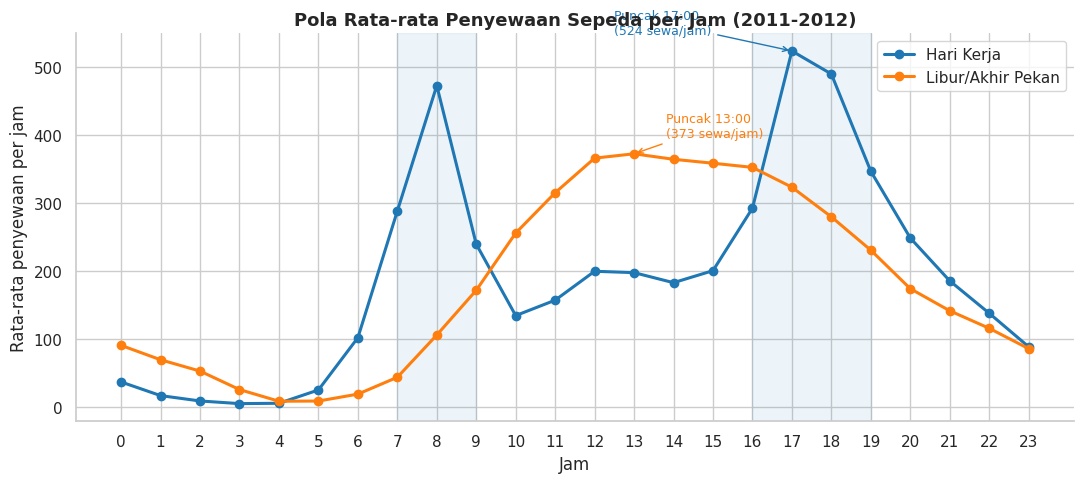

In [18]:
fig, ax = plt.subplots(figsize=(11, 5))
warna = {'Hari Kerja': '#1f77b4', 'Libur/Akhir Pekan': '#ff7f0e'}
for tipe in pola_jam.columns:
    ax.plot(pola_jam.index, pola_jam[tipe], marker='o', lw=2.2, label=tipe, color=warna[tipe])
    jam_puncak = pola_jam[tipe].idxmax()
    ax.annotate(f'Puncak {jam_puncak}:00\n({pola_jam[tipe].max():.0f} sewa/jam)', xy=(jam_puncak, pola_jam[tipe].max()),
                xytext=(jam_puncak + (0.8 if tipe == 'Libur/Akhir Pekan' else -4.5), pola_jam[tipe].max() + 25),
                arrowprops=dict(arrowstyle='->', color=warna[tipe]), color=warna[tipe], fontsize=9)
ax.axvspan(7, 9, color='#1f77b4', alpha=.08); ax.axvspan(16, 19, color='#1f77b4', alpha=.08)
ax.set_xticks(range(24)); ax.set_xlabel('Jam'); ax.set_ylabel('Rata-rata penyewaan per jam')
ax.set_title('Pola Rata-rata Penyewaan Sepeda per Jam (2011-2012)', fontsize=13, fontweight='bold')
ax.legend(); sns.despine(); plt.tight_layout(); plt.show()

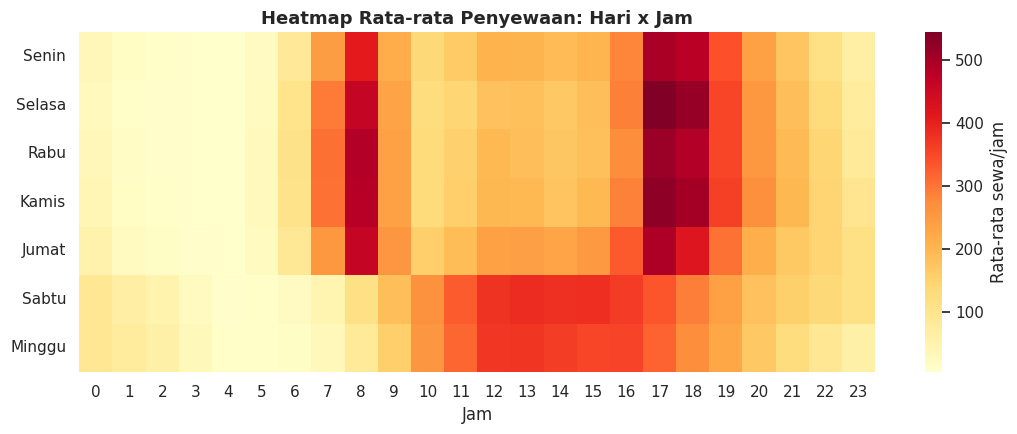

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.5))
heat = hour_full.pivot_table(index='weekday', columns='hr', values='cnt', aggfunc='mean').loc[['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']]
sns.heatmap(heat, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Rata-rata sewa/jam'})
ax.set_title('Heatmap Rata-rata Penyewaan: Hari x Jam', fontsize=13, fontweight='bold'); ax.set_xlabel('Jam'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

### Pertanyaan 2: Berapa persen penurunan penyewaan harian pada cuaca buruk dibandingkan cuaca cerah di tiap musim?

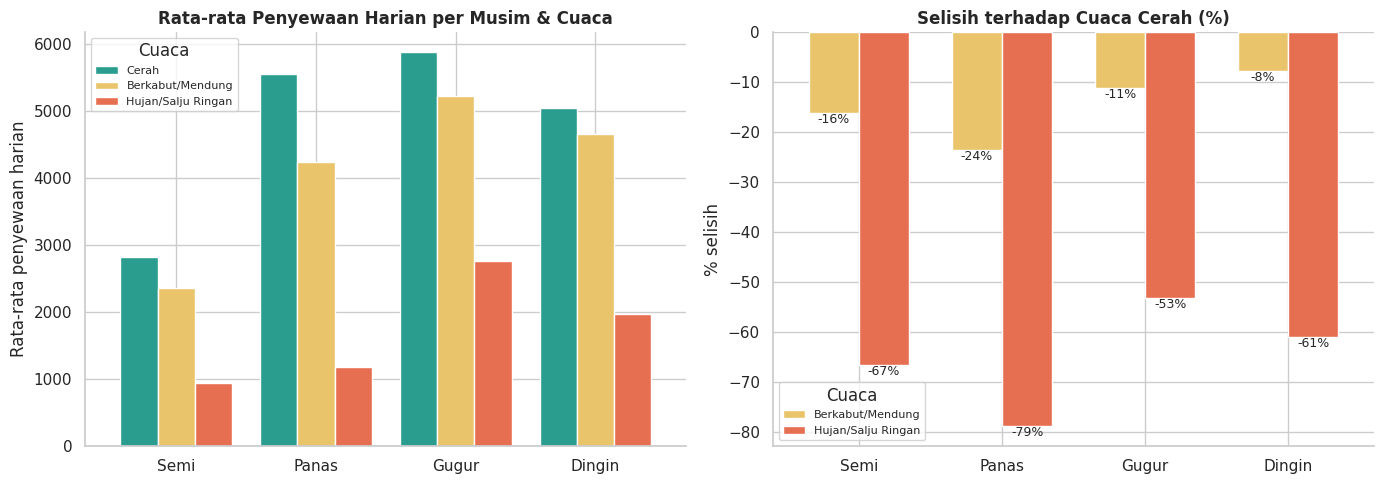

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
musim_cuaca.plot(kind='bar', ax=axes[0], color=['#2a9d8f', '#e9c46a', '#e76f51'], width=.8)
axes[0].set_title('Rata-rata Penyewaan Harian per Musim & Cuaca', fontweight='bold')
axes[0].set_xlabel(''); axes[0].set_ylabel('Rata-rata penyewaan harian'); axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Cuaca', fontsize=8)

pen = penurunan[['Berkabut/Mendung', 'Hujan/Salju Ringan']]
pen.plot(kind='bar', ax=axes[1], color=['#e9c46a', '#e76f51'], width=.7)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.0f%%', fontsize=9)
axes[1].set_title('Selisih terhadap Cuaca Cerah (%)', fontweight='bold')
axes[1].set_xlabel(''); axes[1].set_ylabel('% selisih'); axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Cuaca', fontsize=8)
sns.despine(); plt.tight_layout(); plt.show()

### Pertanyaan 3: Berapa pertumbuhan penyewaan bulanan 2012 dibanding 2011?

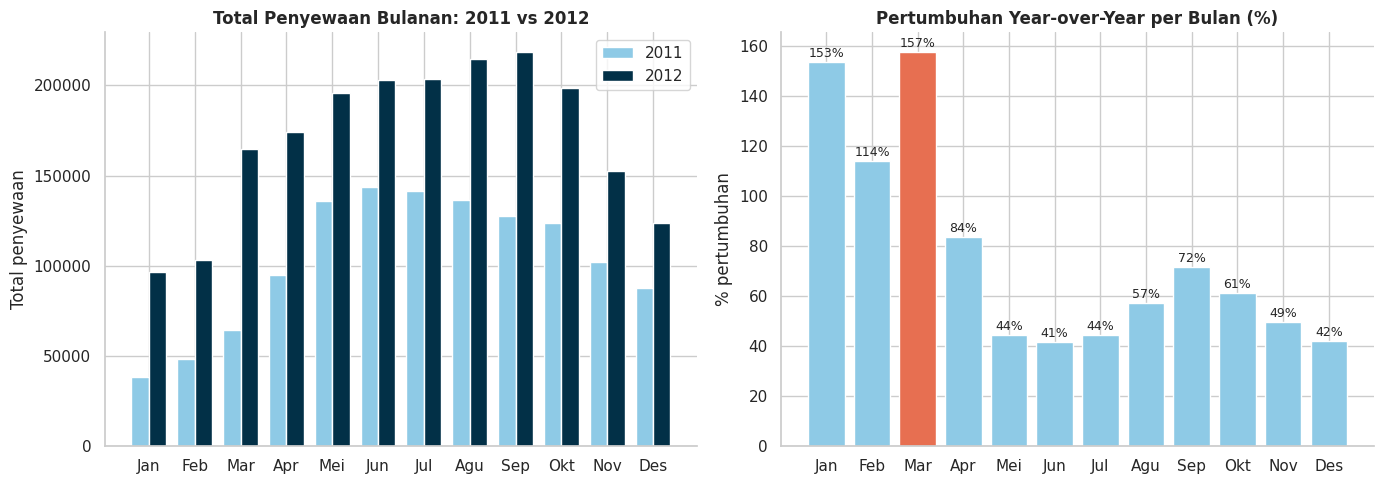

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(12); lebar = .38
axes[0].bar(x - lebar / 2, bulanan[2011], lebar, label='2011', color='#8ecae6')
axes[0].bar(x + lebar / 2, bulanan[2012], lebar, label='2012', color='#023047')
axes[0].set_xticks(x); axes[0].set_xticklabels(bulanan.index)
axes[0].set_title('Total Penyewaan Bulanan: 2011 vs 2012', fontweight='bold'); axes[0].set_ylabel('Total penyewaan'); axes[0].legend()

axes[1].bar(bulanan.index, bulanan['yoy_%'], color=np.where(bulanan['yoy_%'] == bulanan['yoy_%'].max(), '#e76f51', '#8ecae6'))
for i, v in enumerate(bulanan['yoy_%']):
    axes[1].text(i, v + 2, f'{v:.0f}%', ha='center', fontsize=9)
axes[1].set_title('Pertumbuhan Year-over-Year per Bulan (%)', fontweight='bold'); axes[1].set_ylabel('% pertumbuhan')
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- Hari kerja memiliki dua puncak yang jelas pada pukul 08:00 dan 17:00 (pola komuter), sedangkan libur/akhir pekan memuncak sekitar pukul 13:00 dengan intensitas lebih rendah.
- Cuaca berkabut/mendung menurunkan penyewaan sekitar 17% dan hujan/salju ringan sekitar 63% dibanding cuaca cerah.
- Pertumbuhan YoY positif sepanjang tahun, terkuat pada Januari-Maret, dan melambat pada Mei-Juli.

## Analisis Lanjutan (Opsional)

Teknik yang digunakan adalah **Manual Grouping** dan **Binning** (tanpa algoritma *machine learning*):
1. **Manual grouping** jam menjadi segmen waktu (Dini Hari, Pagi, Siang, Sore, Malam).
2. **Binning** suhu menjadi kategori (Dingin, Sejuk, Hangat, Panas).
3. **Binning** tingkat permintaan harian menjadi Rendah / Sedang / Tinggi berdasarkan kuantil.

In [22]:
# 1. Manual grouping segmen waktu
hour_full['segmen_waktu'] = pd.cut(hour_full['hr'], bins=[-1, 5, 9, 15, 19, 23],
                                   labels=['Dini Hari (00-05)', 'Pagi (06-09)', 'Siang (10-15)', 'Sore (16-19)', 'Malam (20-23)'])
segmen = hour_full.pivot_table(index='segmen_waktu', columns='day_type', values='cnt', aggfunc='mean', observed=True).round(1)
segmen

day_type,Hari Kerja,Libur/Akhir Pekan
segmen_waktu,,
Dini Hari (00-05),16.0,42.3
Pagi (06-09),275.7,84.8
Siang (10-15),178.6,338.9
Sore (16-19),413.5,296.7
Malam (20-23),165.1,129.1


In [23]:
# 2. Binning suhu & 3. Binning tingkat permintaan harian
day_clean['kategori_suhu'] = pd.cut(day_clean['temp'], bins=[0, 10, 20, 30, 50], labels=['Dingin (<10°C)', 'Sejuk (10-20°C)', 'Hangat (20-30°C)', 'Panas (>30°C)'])
day_clean['tingkat_permintaan'] = pd.qcut(day_clean['cnt'], q=3, labels=['Rendah', 'Sedang', 'Tinggi'])

suhu = day_clean.groupby('kategori_suhu', observed=True)['cnt'].agg(['count', 'mean']).round(0)
display(suhu)

tabel_silang = pd.crosstab(day_clean['season'], day_clean['tingkat_permintaan'], normalize='index').loc[urutan_musim].mul(100).round(1)
display(tabel_silang)

,count,mean
kategori_suhu,,
Dingin (<10°C),60,1678.0
Sejuk (10-20°C),299,3692.0
Hangat (20-30°C),300,5662.0
Panas (>30°C),72,5410.0


tingkat_permintaan,Rendah,Sedang,Tinggi
season,,,
Semi,77.3,18.2,4.4
Panas,20.1,38.6,41.3
Gugur,6.9,42.0,51.1
Dingin,30.3,34.3,35.4


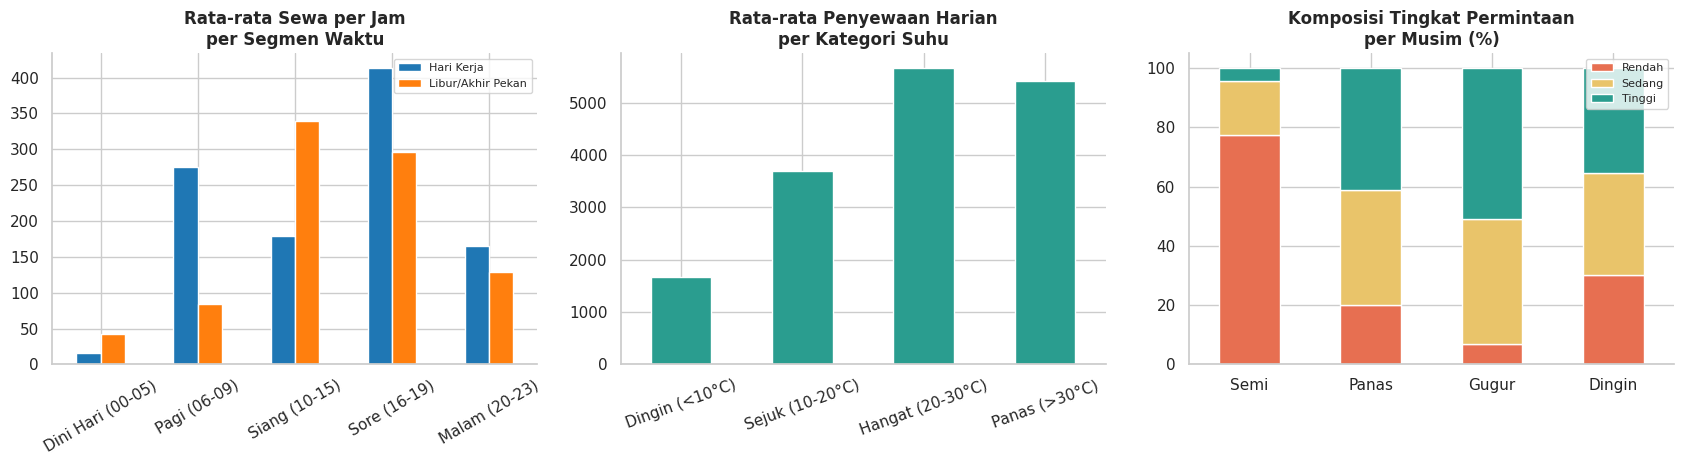

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
segmen.plot(kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e']); axes[0].set_title('Rata-rata Sewa per Jam\nper Segmen Waktu', fontweight='bold')
axes[0].set_xlabel(''); axes[0].tick_params(axis='x', rotation=30); axes[0].legend(fontsize=8)
suhu['mean'].plot(kind='bar', ax=axes[1], color='#2a9d8f'); axes[1].set_title('Rata-rata Penyewaan Harian\nper Kategori Suhu', fontweight='bold')
axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=20)
tabel_silang.plot(kind='bar', stacked=True, ax=axes[2], color=['#e76f51', '#e9c46a', '#2a9d8f']); axes[2].set_title('Komposisi Tingkat Permintaan\nper Musim (%)', fontweight='bold')
axes[2].set_xlabel(''); axes[2].tick_params(axis='x', rotation=0); axes[2].legend(fontsize=8, loc='upper right')
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**
- Segmen **Pagi** dan **Sore** adalah segmen tersibuk pada hari kerja, sedangkan pada libur/akhir pekan segmen **Siang** yang tertinggi.
- Penyewaan meningkat tajam seiring suhu naik hingga kategori **Hangat (20-30 °C)**; pada suhu dingin (<10 °C) penyewaan hanya sekitar sepertiga dari kategori hangat.
- Musim semi didominasi hari dengan permintaan rendah, sedangkan musim panas dan gugur didominasi hari berpermintaan tinggi.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada hari kerja, permintaan memuncak dua kali, pukul 08:00 (sekitar 473 sewa/jam) dan 17:00 (sekitar 524 sewa/jam), mengikuti jam berangkat dan pulang kerja. Pada libur/akhir pekan hanya ada satu puncak pukul 13:00 (sekitar 373 sewa/jam). Pengguna *registered* mendominasi hari kerja, sedangkan porsi pengguna kasual lebih besar pada akhir pekan.
- **Conclusion pertanyaan 2:** Dibanding cuaca cerah (rata-rata sekitar 4.877 sewa/hari), cuaca berkabut/mendung menurunkan penyewaan sekitar 17% dan hujan/salju ringan sekitar 63%. Dampak cuaca buruk paling besar terjadi pada musim panas dan semi (penurunan saat hujan/salju ringan sekitar 79% dan 67%), sedangkan musim gugur paling tahan terhadap cuaca buruk.
- **Conclusion pertanyaan 3:** Total penyewaan 2012 tumbuh sekitar 65% dibanding 2011. Semua bulan tumbuh positif; pertumbuhan tertinggi terjadi pada Maret (sekitar 157%) dan Januari (sekitar 153%), sedangkan yang terendah pada Juni (sekitar 41%) dan Desember (sekitar 42%).

**Rekomendasi Action Item:**
- **Distribusi sepeda:** Pastikan stok sepeda penuh di stasiun area permukiman sebelum 07:00 dan di area perkantoran sebelum 16:00 pada hari kerja; lakukan relokasi (rebalancing) sepeda pada jam sepi (10:00-15:00 dan malam). Pada akhir pekan, fokuskan stok di titik rekreasi sekitar 11:00-15:00.
- **Perawatan terjadwal:** Jadwalkan perawatan massal pada dini hari (00:00-05:00) atau pada hari yang diprakirakan hujan, karena permintaan rendah.
- **Promo cuaca:** Tawarkan insentif/diskon ketika prakiraan cuaca berkabut atau hujan ringan, khususnya di musim semi dan panas, serta tawarkan paket langganan untuk menjaga pengguna terdaftar.
- **Prioritas kampanye:** Perkuat kampanye akuisisi pada Januari-Maret (momentum pertumbuhan tertinggi) dan siapkan program retensi pada Mei-Juli serta Desember saat pertumbuhan melambat.
- **Catatan:** Pertumbuhan 2012 hanya berasal dari dua tahun data, sehingga tren perlu diverifikasi dengan data periode yang lebih panjang.

In [25]:
# Ekspor data bersih untuk dashboard
import os
os.makedirs('dashboard', exist_ok=True)
# main_data.csv  : data harian bersih (dipakai untuk Pertanyaan 2, 3, dan analisis lanjutan)
# hour_clean.csv : data per jam bersih, lengkap 24 jam/hari (dipakai untuk Pertanyaan 1)
day_clean.drop(columns=['kategori_suhu', 'tingkat_permintaan']).to_csv('dashboard/main_data.csv', index=False)
hour_full.drop(columns=['segmen_waktu']).to_csv('dashboard/hour_clean.csv', index=False)
print('Data bersih tersimpan di folder dashboard/ (main_data.csv & hour_clean.csv)')

Data bersih tersimpan di folder dashboard/ (main_data.csv & hour_clean.csv)
